In [1]:
source('../../../R/preamble.R')

# Growth rate

In [2]:
# Pool data from alpha and gamma

gr = bind_rows(
    read.tsv('../../../datasets/growth_curves/2025-02-27_AF_alpha/group_params_esch_AF_alpha.tsv') %>% mutate(run='1'),
    read.tsv('../../../datasets/growth_curves/2025-03-23_AF_gamma/group_params_esch_AF_gamma.tsv') %>% mutate(run='2'),
    )

gr_sum =
gr %>%
    group_by(strain) %>%
    summarise(
        tau_mean = mean(tau), tau_min = mean(tau) - sd(tau), tau_max = mean(tau) + sd(tau),
        tau_lab = paste(round(median(tau),1), sep = '±')
    )

In [3]:
size(2.5, 4.5)

library(ggh4x)

wt_color = pal[1]
ev_color = w

growth_rate_by_experiment =
ggplot() +
    aes(x = gen * 2.5, y = tau, col = run) +

    ycont(15, 22) +

    #geom_rect(data = gr_sum %>% filter(strain == 'WT'), col = NA, alpha = 0.1, xmin = 0, xmax = 10, aes(ymin = tau_min, ymax = tau_max), fill = wt_color) +
    #geom_hline(data = gr_sum %>% filter(strain == 'WT') %>% select(-strain), aes(yintercept = tau_mean), col = wt_color, lty = 2, lwd = 0.2) +

    facet_grid(paste('Lineage', strain)~.) +

    scale_x_continuous(breaks = 2.5*seq(0, 60, 6)) +

    geom_beeswarm(
        data = gr %>% filter(strain != 'WT'),
        cex = 2.5, pch = 21, size = 1.5, stroke = 0.4, fill = ev_color
    ) +

    geom_beeswarm(
        data = gr %>% filter(strain == 'WT') %>% select(-strain),
        cex = 2.5, pch = 21, size = 1.5, stroke = 0.4, fill = ev_color
    ) +

    #theme(legend.position = 'top') +
    nl +

    labs(x = 'Generations (×1000)', y = 'Doubling time (min)', col = 'Experiment')

# Growth dynamics

In [4]:
d = bind_rows(
    read.tsv('../../../datasets/growth_curves/2025-02-27_AF_alpha/growth_dynamics_esch_AF_alpha.tsv') %>% mutate(run='1'),
    read.tsv('../../../datasets/growth_curves/2025-03-23_AF_gamma/growth_dynamics_esch_AF_gamma.tsv') %>% mutate(run='2'),
    )# %>% 
    #filter(strain %in% c('F','WT')) # only show one example

In [5]:
size(2, 7)

bw = 0.01
bins = seq(0, 1.5, bw)
max_od = 0.8

growth_dynamics_by_experiment =
d %>% 
    filter(o_filt <= max_od) %>% 
    mutate(
        genk = fct_reorder(ifelse(strain=='WT', 'Ancestor', paste0(gen * 2.5, ',000 gen.')), gen),
        gr_filt = 60/tau_filt,
        o_bin = bins[cut(o_filt, bins, labels = F)] + bw/2
    ) %>% 

    group_by(run, strain, gen, genk, o_bin) %>%
    summarise(
        gr_m = mean(gr_filt),
        gr_min = min(gr_filt),
        gr_max = max(gr_filt)
    ) %>% 
    ungroup() %>%
    filter(strain!='WT') %>% 
    
ggplot() + aes(
        o_bin, 
        gr_m, min=gr_min, max=gr_max,
        col = run, fill = run
    ) +

    xcont(0, max_od, breaks = seq(0, 1.5, 0.6)) + ycont() +
    facet_grid(paste('Lineage', strain)~genk) +

    geom_ribbon(lwd = 0, alpha = 0.2) +
    geom_line(lwd = 0.3) +

    guides(
        color = guide_legend(override.aes = list(
        #linetype = 0,
        #shape = 1,
        alpha = 0.5
    ))) +
    theme(
        legend.key.size = unit(4,'mm'),
        legend.position = 'bottom',
        legend.title = element_text(face='bold', size=9),
        legend.text = element_text(size=9)
    ) +

    labs(x = 'OD (600nm)', y = 'Growth rate (/h)', col = 'Experiment', fill = 'Experiment')

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by run, strain, gen, genk, and o_bin.
ℹ Output is grouped by run, strain, gen, and genk.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(run, strain, gen, genk, o_bin))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_ribbon()`).”


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_ribbon()`).”


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_ribbon()`).”


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


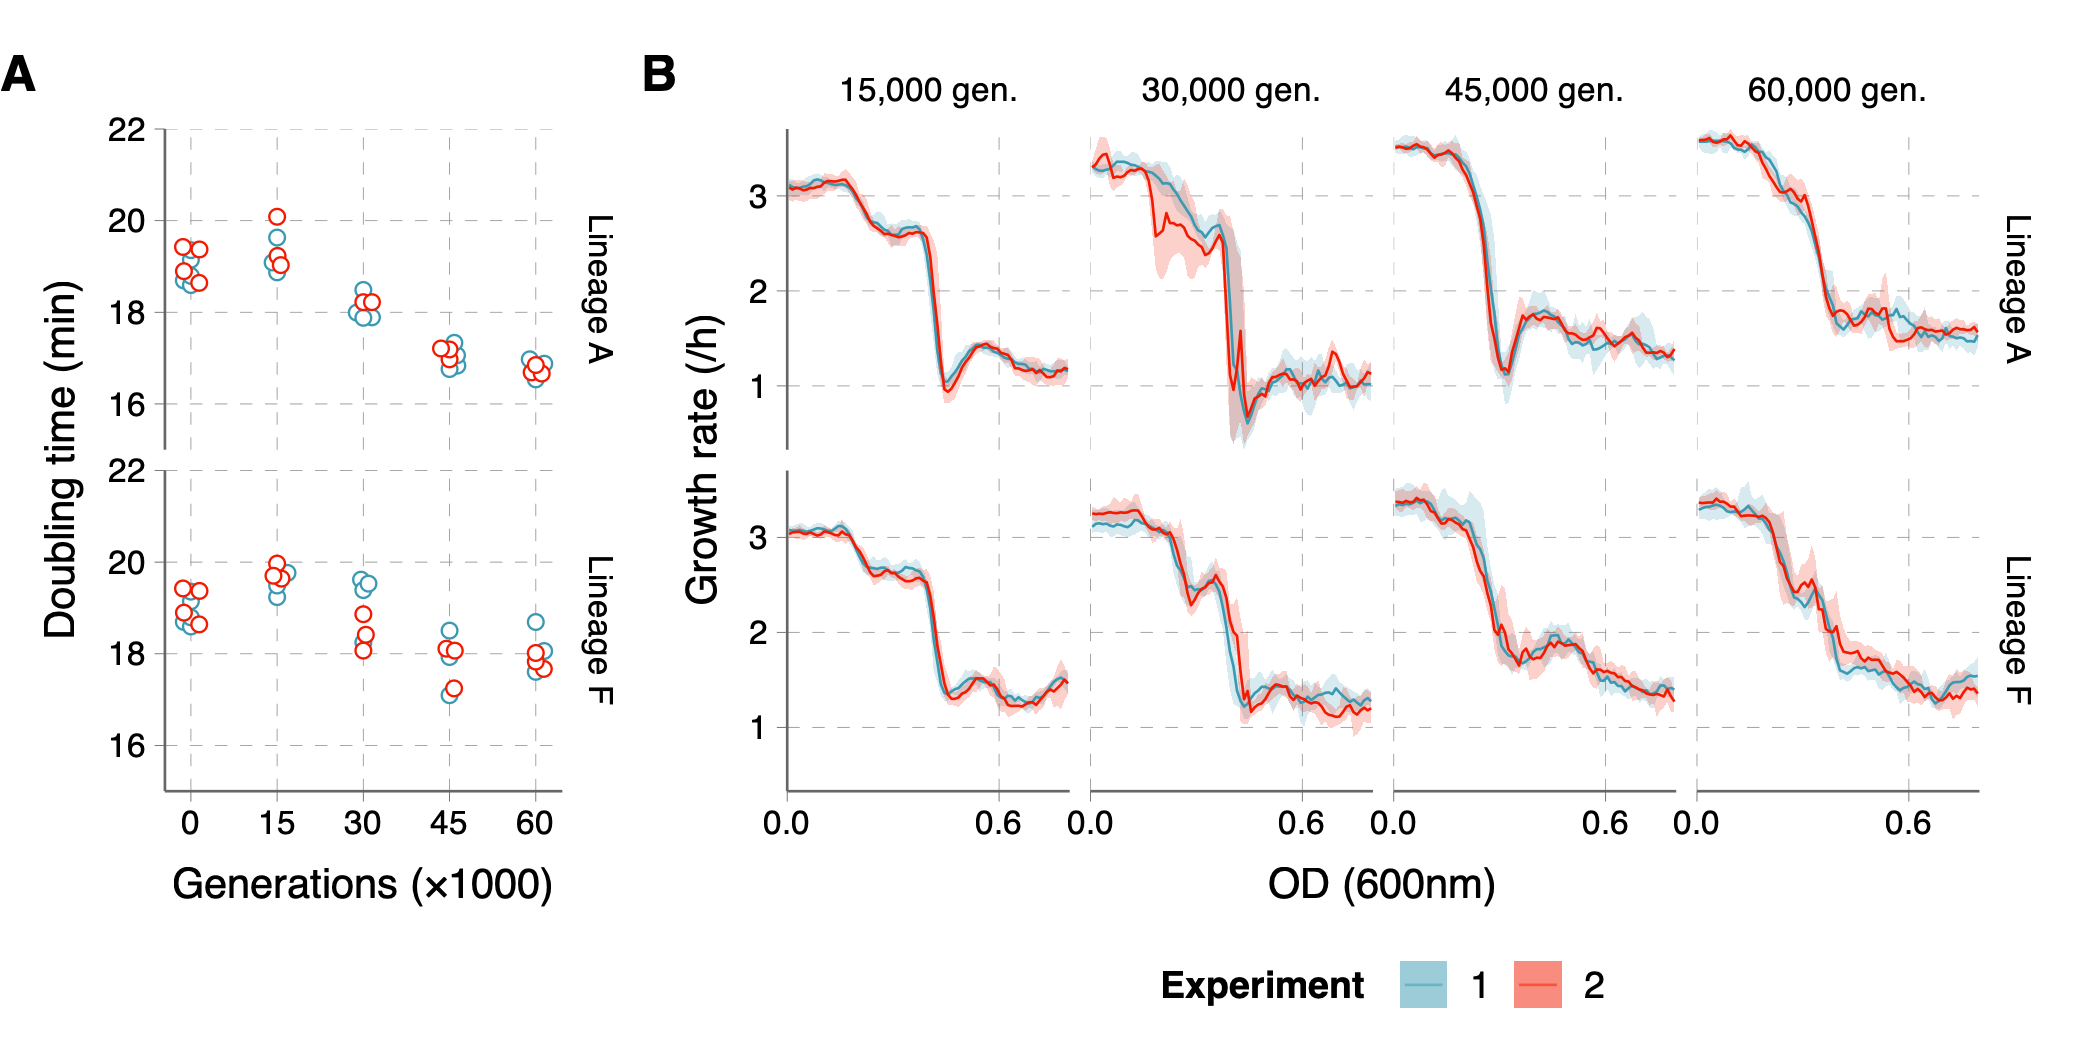

In [6]:
size(3.5, 7)
letters = function(...){element_text(size = 12, hjust=0, vjust=0, face = 'bold', margin = margin(...))}

(
    growth_rate_by_experiment |
    growth_dynamics_by_experiment
) +
    plot_layout(widths=c(1, 3)) +
    plot_annotation(tag_levels = 'A') & theme(plot.tag = letters(0, 0, -10, -10))

psave('Plots/growth_curve_reproductibility')

# Pooled version

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by strain, gen, and o_smooth.
ℹ Output is grouped by strain and gen.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(strain, gen, o_smooth))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


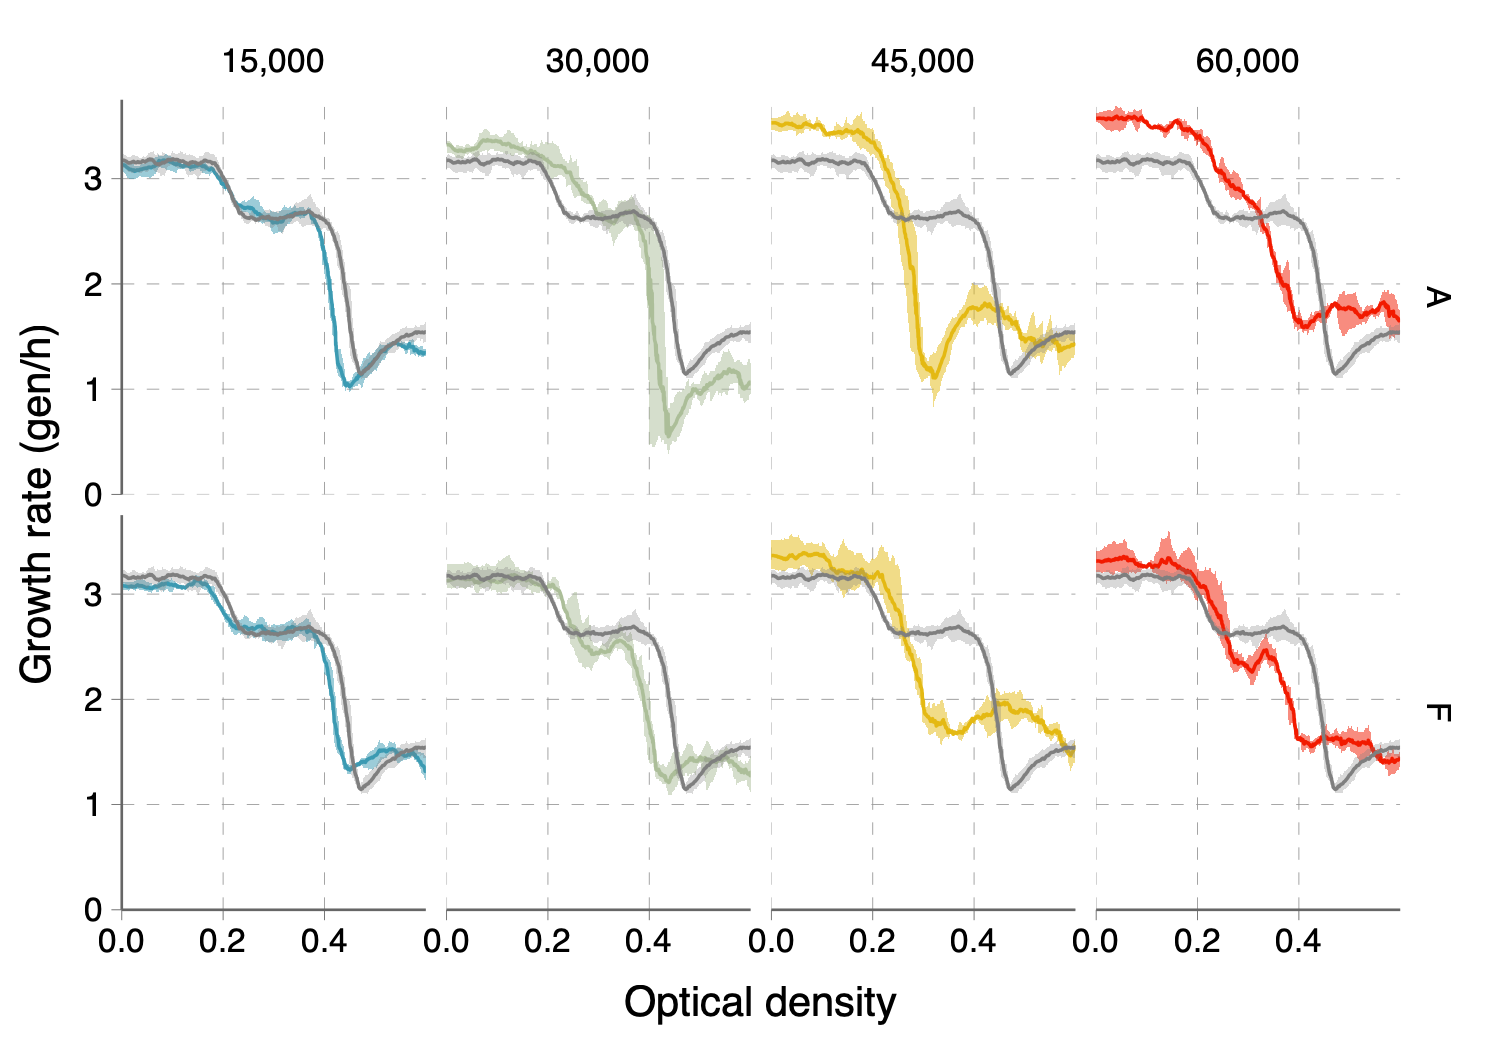

In [7]:
max_od = 0.6
resolution = 1e-4

d_interp =
d %>% 
    filter(run == 1) %>% 
    mutate(gr_filt = 60/tau_filt) %>% 

    group_by(name, strain, gen, rep) %>%
    group_modify(~{
        o_smooth <- seq(0, max_od, by = resolution)
        interp_values <- approx(
          x = .x$o_filt,
          y = .x$gr_filt,
          xout = o_smooth,
          method = "linear",
          rule = 2  # extrapolate if needed
        )
        data.frame(
          o_smooth = interp_values$x,
          gr_smooth = interp_values$y
        )
      }) %>%
    ungroup() 

d_sum =
d_interp %>% 
    group_by(strain, gen, o_smooth) %>%
    summarise(
        m = mean(gr_smooth),
        s = sd(gr_smooth),
        mn = min(gr_smooth), mx = max(gr_smooth)
        ) %>%
    ungroup()

ribbon_alpha = 0.5
ribbon_alpha_wt = 0.3

lwd = 0.4
lwd_wt = 0.4

wt_color = 'grey50'

size(3.5, 5)

d_sum %>% 
    filter(strain != 'WT', strain != 'E') %>% 
    mutate(genk = paste0(gen * 2.5, ',000')) %>% 

ggplot() + aes(o_smooth, 
               m, ymin = mn, ymax = mx,
               #ymin = m - s, ymax = m + s,
               col = gen,
               ) +
    nl +
    facet_grid(strain ~ genk) +

    xcont(0, max_od, breaks = seq(0, 0.5, 0.2)) + ycont(0, 3.75, breaks = seq(0, 3, 1)) +

    geom_ribbon(col = NA, alpha = ribbon_alpha, aes(fill = gen)) +
    geom_line(lwd = lwd) +

    geom_ribbon(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = NA, fill = wt_color, alpha = ribbon_alpha_wt) +
    geom_line(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = wt_color, lwd = lwd_wt) +

    #annotate(geom = 'text', x = 0.19, y = 2.7, label = 'WT', size = 3, fontface = 'bold', col = wt_color) +
    #annotate(geom = 'text', x = 0.35, y = 3.1, label = '60k', size = 3, fontface = 'bold', col = pal[2]) +

    labs(x = 'Optical density', y = 'Growth rate (gen/h)')

psave('Plots/growth_rate_vs_od_pooled')

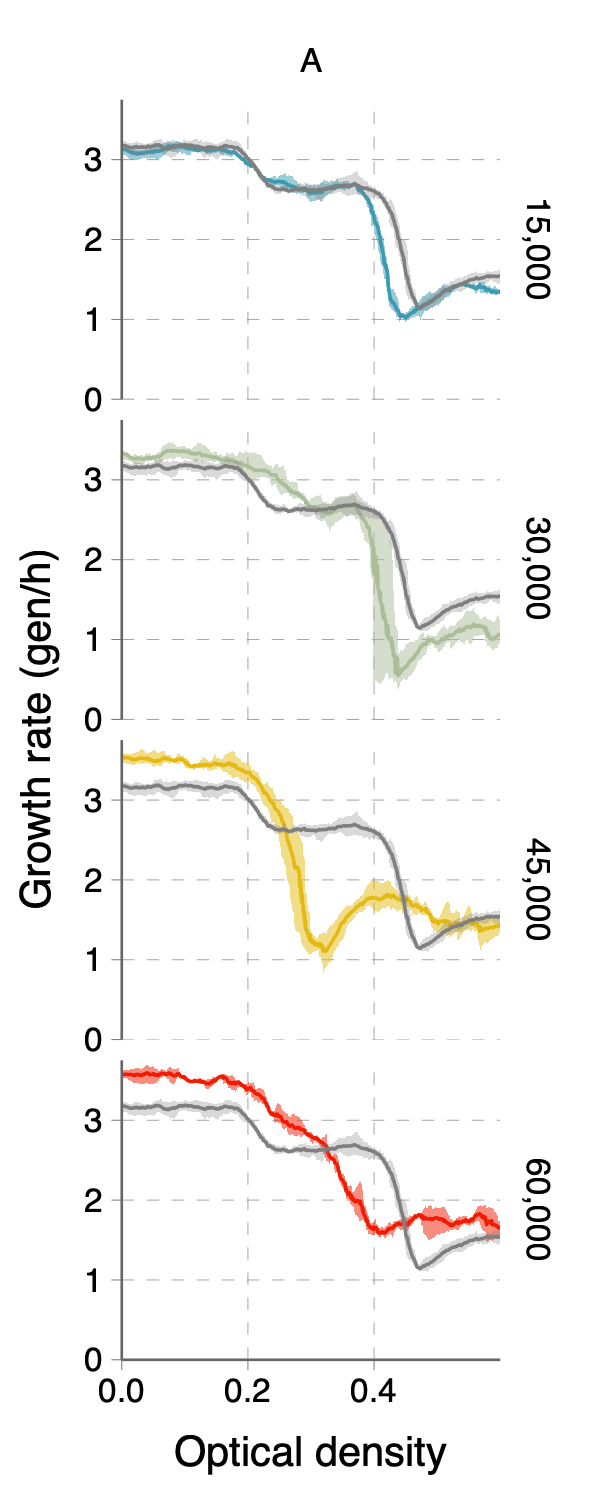

In [8]:
size(5,2)

d_sum %>% 
    filter(strain != 'WT', strain == 'A') %>% 
    mutate(genk = paste0(gen * 2.5, ',000')) %>% 

ggplot() + aes(o_smooth, 
               m, ymin = mn, ymax = mx,
               #ymin = m - s, ymax = m + s,
               col = gen,
               ) +
    nl +
    facet_grid(genk~strain) +

    xcont(0, max_od, breaks = seq(0, 0.5, 0.2)) + ycont(0, 3.75, breaks = seq(0, 3, 1)) +

    geom_ribbon(col = NA, alpha = ribbon_alpha, aes(fill = gen)) +
    geom_line(lwd = lwd) +

    geom_ribbon(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = NA, fill = wt_color, alpha = ribbon_alpha_wt) +
    geom_line(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = wt_color, lwd = lwd_wt) +

    labs(x = 'Optical density', y = 'Growth rate (gen/h)')

saveRDS(last_plot(), 'Plots/GG/separate_dynamics_A.rds')

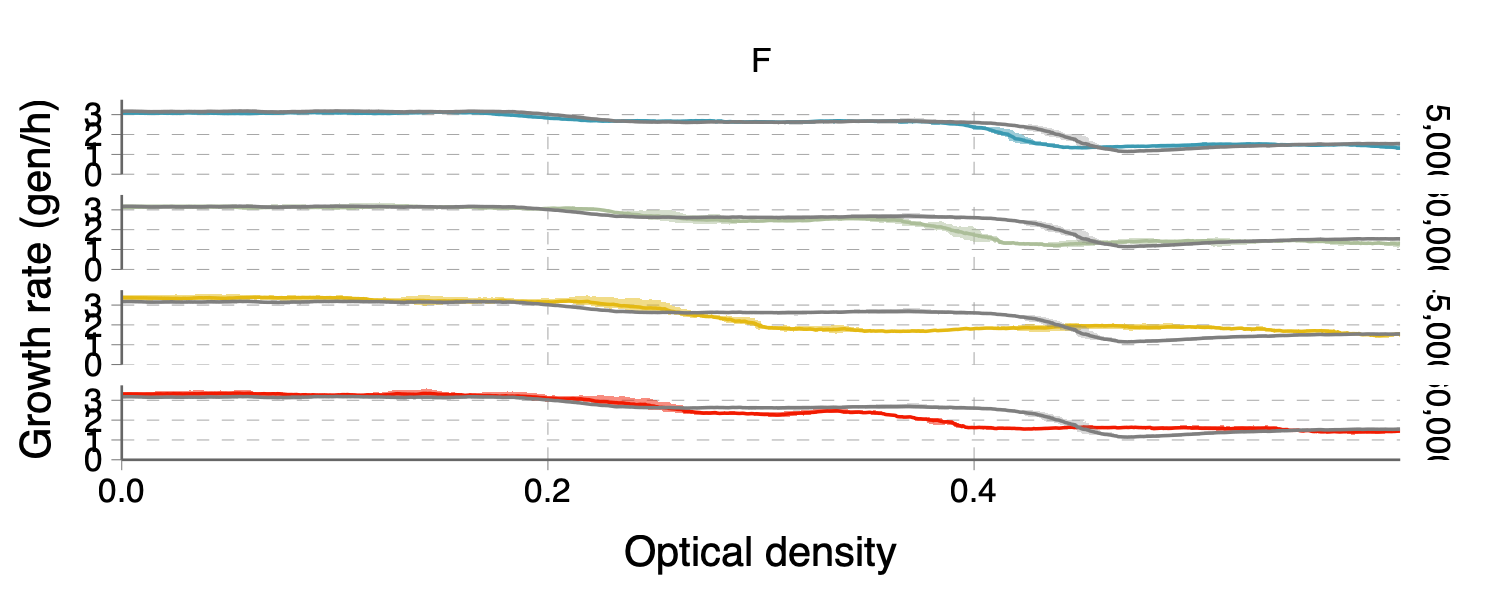

In [9]:
size(2,5)

d_sum %>% 
    filter(strain != 'WT', strain == 'F') %>% 
    mutate(genk = paste0(gen * 2.5, ',000')) %>% 

ggplot() + aes(o_smooth, 
               m, ymin = mn, ymax = mx,
               #ymin = m - s, ymax = m + s,
               col = gen,
               ) +
    nl +
    facet_grid(genk~strain) +

    xcont(0, max_od, breaks = seq(0, 0.5, 0.2)) + ycont(0, 3.75, breaks = seq(0, 3, 1)) +

    geom_ribbon(col = NA, alpha = ribbon_alpha, aes(fill = gen)) +
    geom_line(lwd = lwd) +

    geom_ribbon(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = NA, fill = wt_color, alpha = ribbon_alpha_wt) +
    geom_line(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = wt_color, lwd = lwd_wt) +

    labs(x = 'Optical density', y = 'Growth rate (gen/h)')

saveRDS(last_plot(), 'Plots/GG/separate_dynamics_F.rds')